# 07 — ODE integration: Euler, RK4, and CVODES

**Objectives.** Separate a continuous model from a discrete propagation map, compare accuracy, and use an adaptive integrator. We solve $\dot x_1=x_2$, $\dot x_2=-x_1-0.2x_2+u$. Local error is $O(h^2)$ for Euler and $O(h^5)$ for RK4; accumulated global error is one order lower.


In [1]:
# Make repository-local helpers importable without installing a package.
import sys
from pathlib import Path

repository_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "casadi_tutorial").is_dir()
)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

# Autoreload picks up edits to tutorial models before each notebook cell runs.
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("load_ext", "autoreload")
    ipython.run_line_magic("autoreload", "2")

### Compare explicit integration formulas with CVODES

The cell defines a damped oscillator right-hand side and constructs
one-step Euler and RK4 functions using the editable integration helpers.
It also calls `ca.integrator` with the `cvodes` plugin, passing a dictionary
whose `x`, `p`, and `ode` fields identify the state, held input, and
continuous dynamics. Tight tolerances make the CVODES result a useful
reference for the fixed-step formulas.

The continuous system is

$$
\dot x_0=x_1,\qquad
\dot x_1=-x_0-0.2x_1+u.
$$

Forward Euler uses

$$
x_{k+1}=x_k+h f(x_k,u_k),
$$

whereas classical RK4 uses

$$
x_{k+1}=x_k+\frac{h}{6}(k_1+2k_2+2k_3+k_4),
$$

with the standard four intermediate slopes. The assertion confirms that
RK4 is closer than Euler to the adaptive CVODES solution for this step.

The plotted rollout compares Euler, RK4, and CVODES for both state components $x_0(t)$ and $x_1(t)$ under the same piecewise-constant manipulated input $u(t)$.


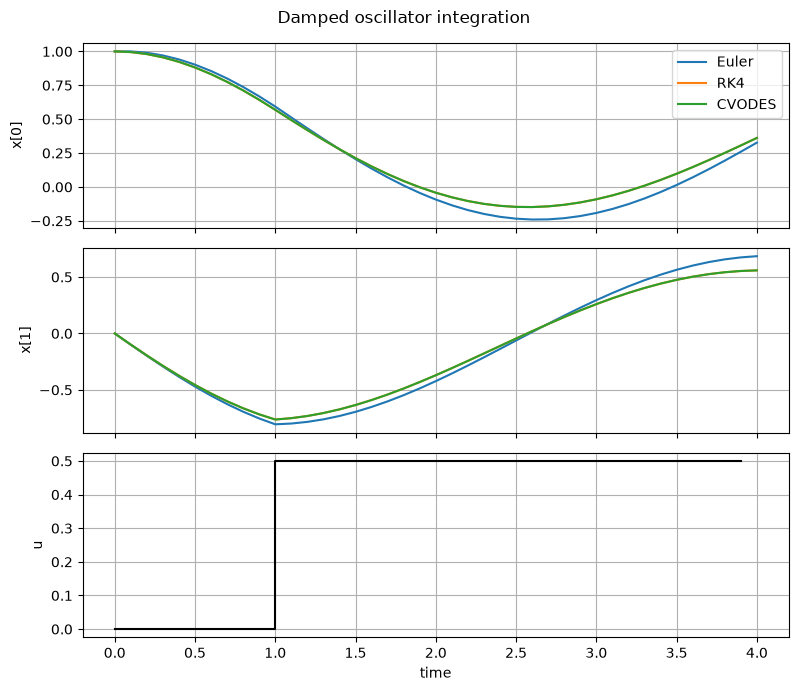

In [2]:
import casadi as ca
import matplotlib.pyplot as plt
import numpy as np

from casadi_tutorial.integration import euler_step, rk4_step


def oscillator_rhs(x, u):
    """Return the damped oscillator state derivative f(x, u)."""
    return ca.vertcat(
        x[1],
        -x[0] - 0.2 * x[1] + u[0],
    )


x = ca.MX.sym("x", 2)
u = ca.MX.sym("u", 1)
step_size = 0.1

euler_function = ca.Function(
    "euler_step",
    [x, u],
    [euler_step(oscillator_rhs, x, u, step_size)],
    ["x", "u"],
    ["x_next"],
)
rk4_function = ca.Function(
    "rk4_step",
    [x, u],
    [rk4_step(oscillator_rhs, x, u, step_size)],
    ["x", "u"],
    ["x_next"],
)

# p is the integrator's held parameter field; it carries manipulated input u.
ode_problem = {"x": x, "p": u, "ode": oscillator_rhs(x, u)}
cvodes_function = ca.integrator(
    "cvodes_step",
    "cvodes",
    ode_problem,
    0.0,
    step_size,
    {"abstol": 1e-10, "reltol": 1e-10},
)

number_of_steps = 40
x_time = step_size * np.arange(number_of_steps + 1)
u_time = step_size * np.arange(number_of_steps)
u_history = np.where(u_time >= 1.0, 0.5, 0.0)
x_euler = np.zeros((number_of_steps + 1, 2))
x_rk4 = np.zeros_like(x_euler)
x_cvodes = np.zeros_like(x_euler)
x_euler[0] = x_rk4[0] = x_cvodes[0] = [1.0, 0.0]

for index, u_value in enumerate(u_history):
    x_euler[index + 1] = np.asarray(euler_function(x_euler[index], [u_value]).full()).ravel()
    x_rk4[index + 1] = np.asarray(rk4_function(x_rk4[index], [u_value]).full()).ravel()
    x_cvodes[index + 1] = np.asarray(
        cvodes_function(x0=x_cvodes[index], p=[u_value])["xf"].full()
    ).ravel()

# RK4 should be closer than Euler to CVODES after the first fixed step.
assert np.linalg.norm(x_rk4[1] - x_cvodes[1]) < np.linalg.norm(x_euler[1] - x_cvodes[1])

figure, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 7))
for method_name, x_values in (
    ("Euler", x_euler),
    ("RK4", x_rk4),
    ("CVODES", x_cvodes),
):
    axes[0].plot(x_time, x_values[:, 0], label=method_name)
    axes[1].plot(x_time, x_values[:, 1], label=method_name)
axes[0].set_ylabel("x[0]")
axes[1].set_ylabel("x[1]")
axes[0].legend()
axes[0].grid(True)
axes[1].grid(True)
axes[2].step(u_time, u_history, where="post", color="black")
axes[2].set(xlabel="time", ylabel="u")
axes[2].grid(True)
figure.suptitle("Damped oscillator integration")
figure.tight_layout()
plt.show()

A control is typically held piecewise constant over each interval. Integration failure can signal tight tolerances, stiffness, discontinuities, an invalid domain, or a bad model—not merely a need for more solver iterations. CVODES uses adaptive internal steps; the outer control grid is still yours.

**Common mistake:** silently mixing seconds and hours. **Recap:** validate a simple fixed-step map against an adaptive integrator before embedding it in an OCP. [Exercises](../exercises/03_integration.ipynb).
